# Issue #312 — explicit within-issue joint action cube

Every exact-B0-common-support 2023 issue receives exactly 512 CNY2 tickets. The model learns
match selector, candidate pool, outcome direction, N/K, generator and bounded
protection; it cannot skip an issue or reduce its committed budget.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'src' / 'issue312').is_dir())
OUTPUT = ROOT / 'results/issue-312'
decision = json.loads((OUTPUT / 'decision.json').read_text())
decision

{'issue': 312,
 'question': 'explicit within-issue selector, outcome and protection joint action value',
 'decision': {'verdict': 'NO_INCREMENT',
  'promotable': False,
  'eligible_issue_policy': 'ALL_ISSUES_ACTIVE_NO_LEARNED_SKIP',
  'committed_tickets_per_issue': 512,
  'committed_stake_per_issue_cny': 1024.0,
  'evaluation_physical_seeds': 31,
  'primary_2023_median_terminal_capital_cny': 70795.71844827884,
  'primary_2023_median_growth_pct': -29.204281551721156,
  'primary_2023_median_turnover_roi_pct': -59.416262922609775,
  'primary_2023_median_max_drawdown_pct': 30.179676271489207,
  'primary_2023_median_ex_largest_pnl_cny': -35974.61427429434,
  'issue306_2023_median_terminal_capital_cny': 88557.96561706233,
  'issue306_role': 'INTERFACE_ONLY_SECONDARY_COMPARATOR',
  'exact_b0_reference_terminal_capital_cny': 79248.96196799999,
  'exact_b0_reference_turnover_roi_pct': -13.554796545822722,
  'exact_b0_reference_matched_budget_translation': 'UNAVAILABLE_NO_COMMITTED_TICKET_IDENTI

## Frozen design and support

In [2]:
registry = pd.read_csv(OUTPUT / 'action_registry.csv')
marginal = pd.read_csv(OUTPUT / 'action_design_marginals.csv')
pairwise = pd.read_csv(OUTPUT / 'action_design_pairwise_coverage.csv')
display(registry.groupby('is_anchor').size().rename('actions'))
display(marginal.pivot(index='level', columns='factor', values='count').fillna(''))
display(pairwise.sort_values('coverage_fraction').head(10))

is_anchor
False    96
True     96
Name: actions, dtype: int64

factor,generator,k,match_selector,n,outcome_direction,pool_excess,protection
level,,,,,,,
-1,,,,,,120.0,
0,,,,,,25.0,
10,,,,24.0,,,
128,,46.0,,,,,
2,,,,,,22.0,
3,,,,28.0,,,
32,,48.0,,,,,
4,,,,25.0,,25.0,
5,,,,25.0,,,


,left_factor,right_factor,observed_level_pairs,possible_level_pairs,coverage_fraction
1,n,match_selector,44,48,0.916667
5,n,protection,38,40,0.950000
2,n,pool_excess,32,32,1.000000
0,n,k,32,32,1.000000
3,n,outcome_direction,32,32,1.000000
4,n,generator,24,24,1.000000
6,k,match_selector,24,24,1.000000
7,k,pool_excess,16,16,1.000000
8,k,outcome_direction,16,16,1.000000
9,k,generator,12,12,1.000000


## Development freeze and model receipts

In [3]:
development = pd.read_csv(OUTPUT / 'development_policy_selection.csv')
fits = pd.read_csv(OUTPUT / 'pre2023_fit_receipts.csv')
display(development)
display(fits.groupby('condition').agg(fits=('model_seed','size'),
    converged=('converged','all'), max_iterations=('iterations','max'),
    train_issues=('train_issues','max')))

,family,development_oof_fixed_budget_pnl_cny,selected_as_primary
0,TAIL,-27907.687558,True
1,MEAN,-34473.061049,False


,fits,converged,max_iterations,train_issues
condition,,,,
IDENTITY_SHUFFLED,5,True,84,179
ISSUE_BLOCK_SHUFFLED,5,True,255,179
LEARNED,5,True,276,179


## Fixed-exposure capital, tails and attribution

,condition,median_terminal_capital_cny,median_capital_growth_pct,median_turnover_roi_pct,median_max_drawdown_pct,median_ex_largest_pnl_cny,median_positive_issue_rate,median_tail_5x_rate
11,ORACLE_DIAGNOSTIC,309422.564499,209.422564,426.071298,3.982218,170039.264744,0.500000,0.395833
5,IDENTITY_SHUFFLED,95807.814024,-4.192186,-8.529024,15.236383,-17838.964740,0.208333,0.020833
6,ISSUE306_PRIMARY,88557.965617,-11.442034,-23.278879,16.971145,-17283.989020,0.187500,0.041667
4,FIXED_N7_K512_WOR,87984.267911,-12.015732,-24.446070,16.126167,-19141.389470,0.208333,0.041667
0,ABLATE_OUTCOME,75231.503492,-24.768497,-50.391635,27.322049,-33119.287741,0.104167,0.020833
8,JOINT_MEAN,73961.630993,-26.038369,-52.975197,26.038369,-30070.284209,0.104167,0.000000
7,ISSUE_BLOCK_SHUFFLED,71458.403381,-28.541597,-58.068027,28.578735,-31001.351448,0.104167,0.000000
9,JOINT_PRIMARY,70795.718448,-29.204282,-59.416263,30.179676,-35974.614274,0.104167,0.020833
10,JOINT_TAIL,70795.718448,-29.204282,-59.416263,30.179676,-35974.614274,0.104167,0.020833
2,ABLATE_SELECTOR,68261.351610,-31.738648,-64.572445,31.738648,-37463.171513,0.104167,0.020833


,condition,issues,stake_cny,pnl_cny,terminal_capital_cny,turnover_roi_pct,matched_budget_translation
0,EXACT_B0_BEST_FULL_ONE_BUNDLE,48,153090.0,-20751.038032,79248.961968,-13.554797,UNAVAILABLE_NO_COMMITTED_TICKET_IDENTITIES


,ablation,median_seed_lift_cny,positive_seed_fraction,mean_issue_lift_cny,positive_issue_fraction,ex_largest_issue_lift_cny
0,ABLATE_SELECTOR,583.509279,0.548387,-54.542867,0.083333,-3337.805767
1,ABLATE_OUTCOME,-807.661254,0.387097,-39.619251,0.020833,-1901.724055
2,ABLATE_PROTECTION,4359.349543,0.806452,67.532895,0.062500,-1308.883137


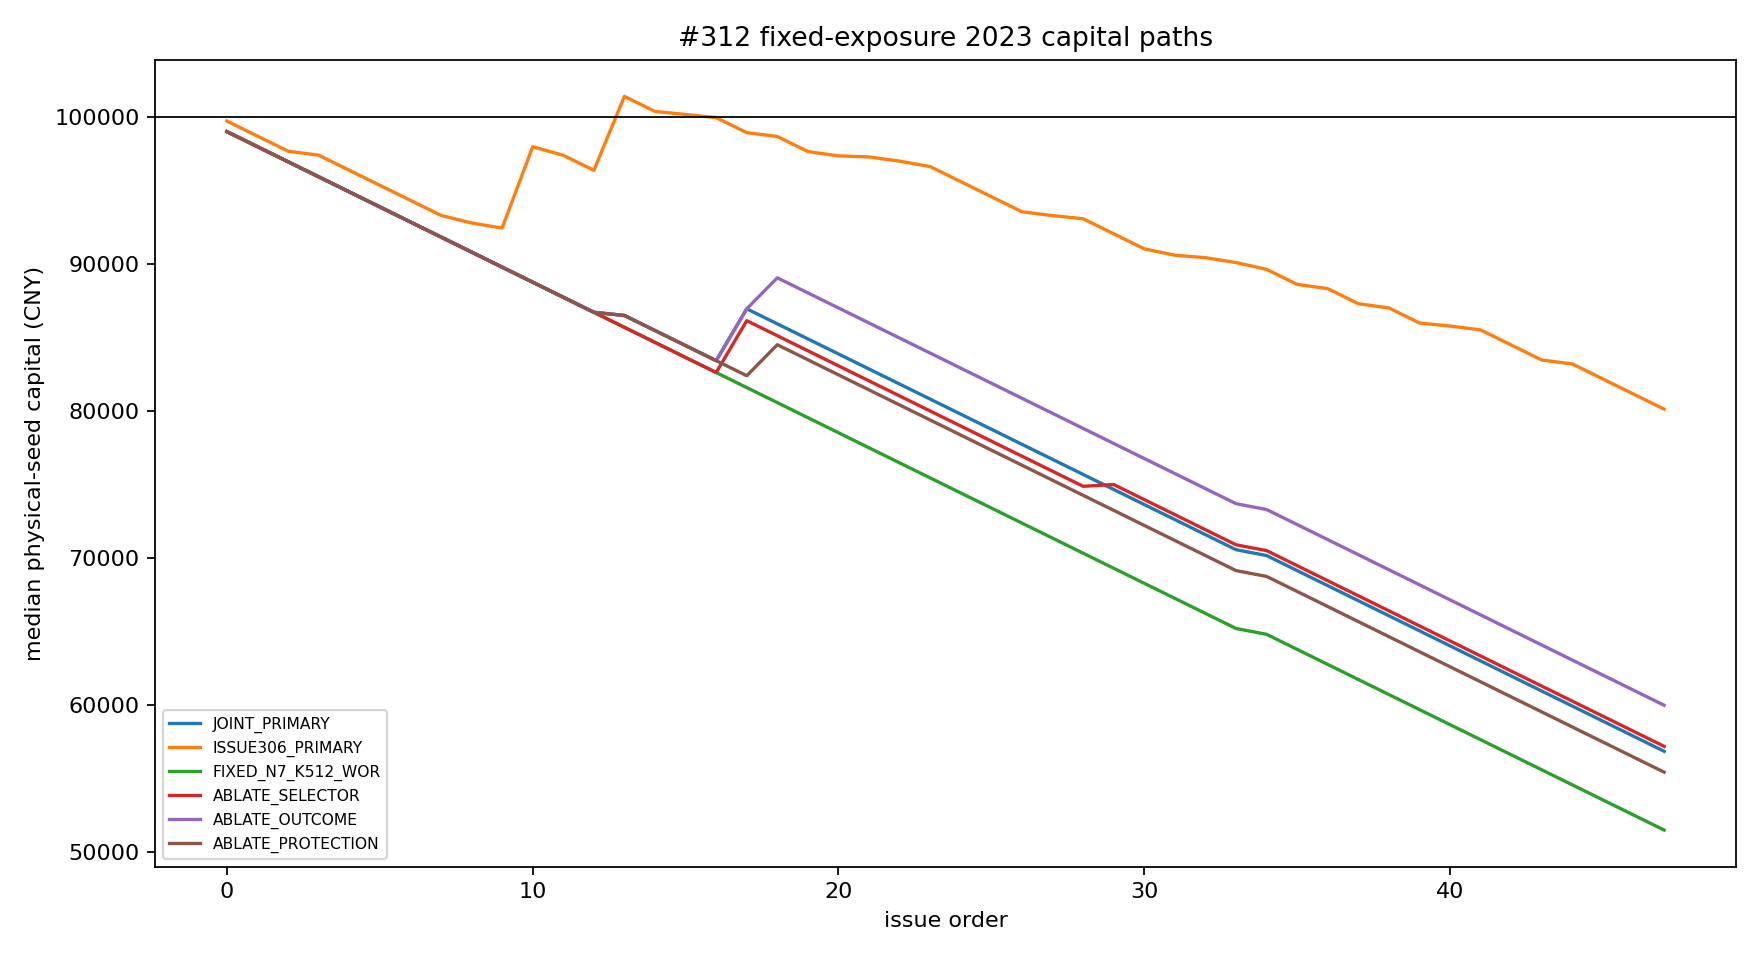

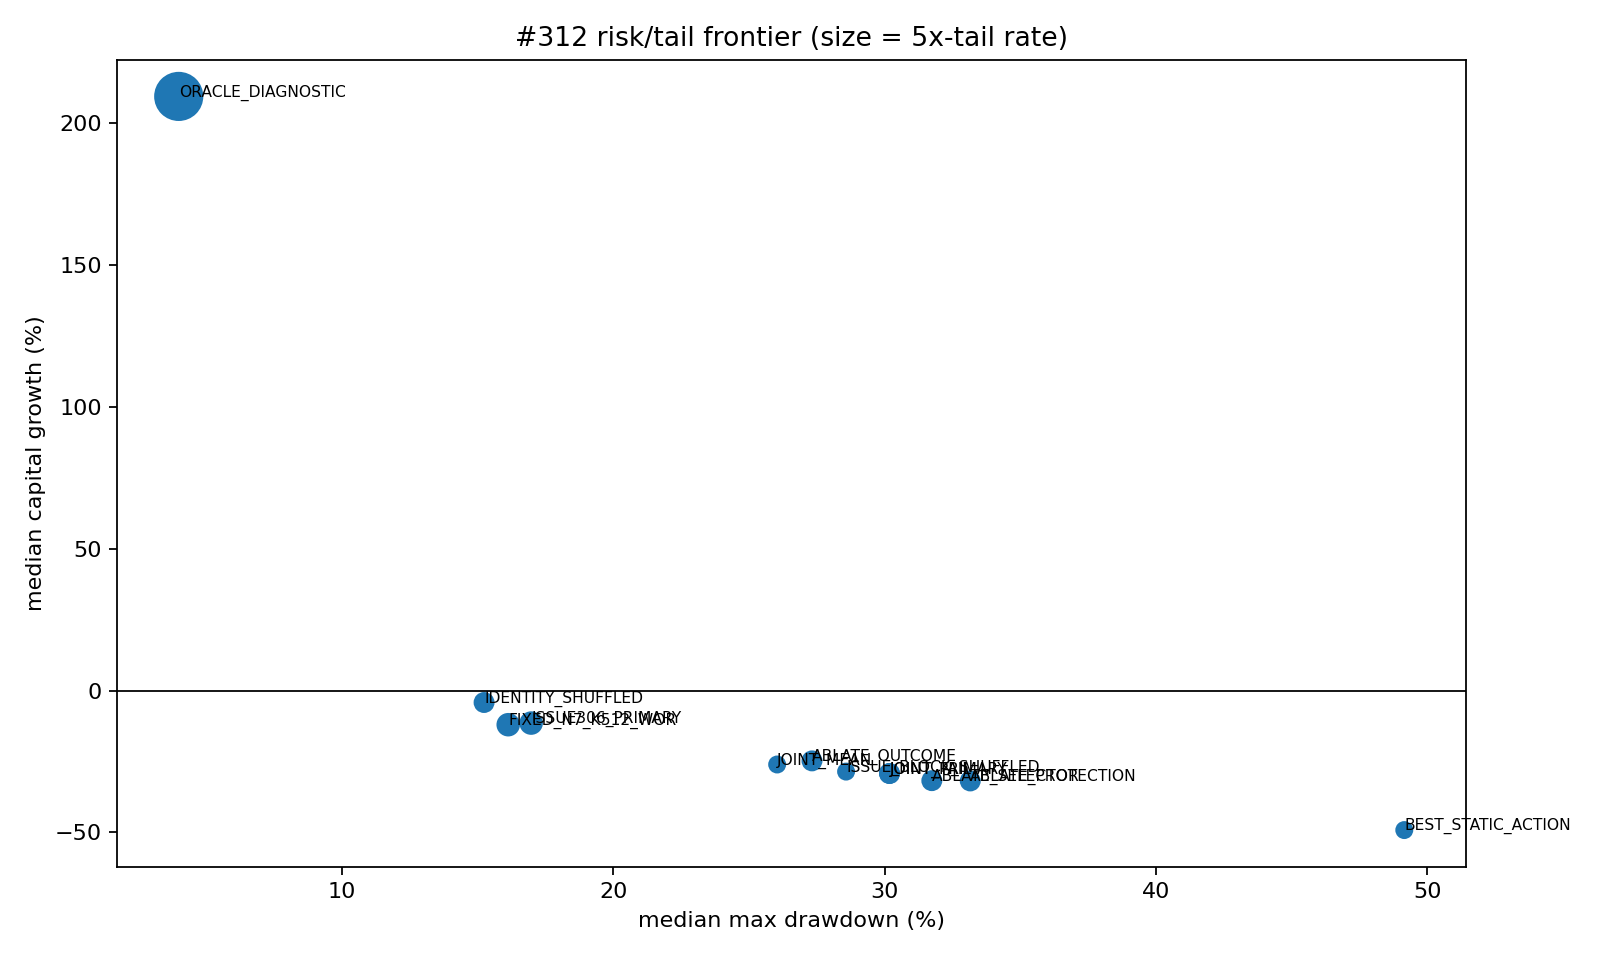

In [4]:
summary = pd.read_csv(OUTPUT / 'policy_summary.csv')
cols = ['condition','median_terminal_capital_cny','median_capital_growth_pct',
        'median_turnover_roi_pct','median_max_drawdown_pct',
        'median_ex_largest_pnl_cny','median_positive_issue_rate',
        'median_tail_5x_rate']
display(summary[cols].sort_values('median_terminal_capital_cny', ascending=False))
display(pd.read_csv(OUTPUT / 'exact_b0_reference_2023.csv'))
display(pd.read_csv(OUTPUT / 'factor_attribution.csv'))
display(Image(filename=str(OUTPUT / 'capital_paths_2023.png')))
display(Image(filename=str(OUTPUT / 'risk_tail_frontier_2023.png')))

## Learned parameter distribution and physical null

,n,k,match_selector,pool_excess,outcome_direction,generator,protection,issues,allocated_tickets
14,8,512,BEST_VALUE,0,MARKET_P,WEIGHTED_WOR,ALT_UNCERTAINTY,6,3072
11,6,128,GLOBAL_VALUE,-1,RAW_VALUE,WEIGHTED_WR,NONE,6,3072
5,4,32,GLOBAL_VALUE,4,DIVERGENCE,TOP_VALUE,SOFT_REENTRY_15,5,2560
10,6,128,GLOBAL_VALUE,-1,RAW_VALUE,WEIGHTED_WOR,NONE,5,2560
4,4,8,COLD_EXCLUDABLE,0,RAW_VALUE,TOP_VALUE,ALT_UNCERTAINTY,4,2048
3,3,512,GLOBAL_VALUE,-1,RAW_VALUE,TOP_VALUE,NONE,4,2048
7,5,32,GLOBAL_VALUE,-1,RAW_VALUE,TOP_VALUE,SOFT_REENTRY_15,4,2048
9,6,128,COLD_EXCLUDABLE,0,MARKET_P,TOP_VALUE,SOFT_REENTRY_15,3,1536
15,9,128,DIVERGENCE,4,HYBRID,WEIGHTED_WR,NONE,2,1024
12,7,512,GLOBAL_VALUE,-1,RAW_VALUE,WEIGHTED_WOR,NONE,2,1024


count      2000.000000
mean      83089.280033
std       11924.673295
min       58866.769798
5%        67029.258154
50%       80880.257386
95%      104988.179395
max      131519.468618
Name: median_terminal_capital_cny, dtype: float64

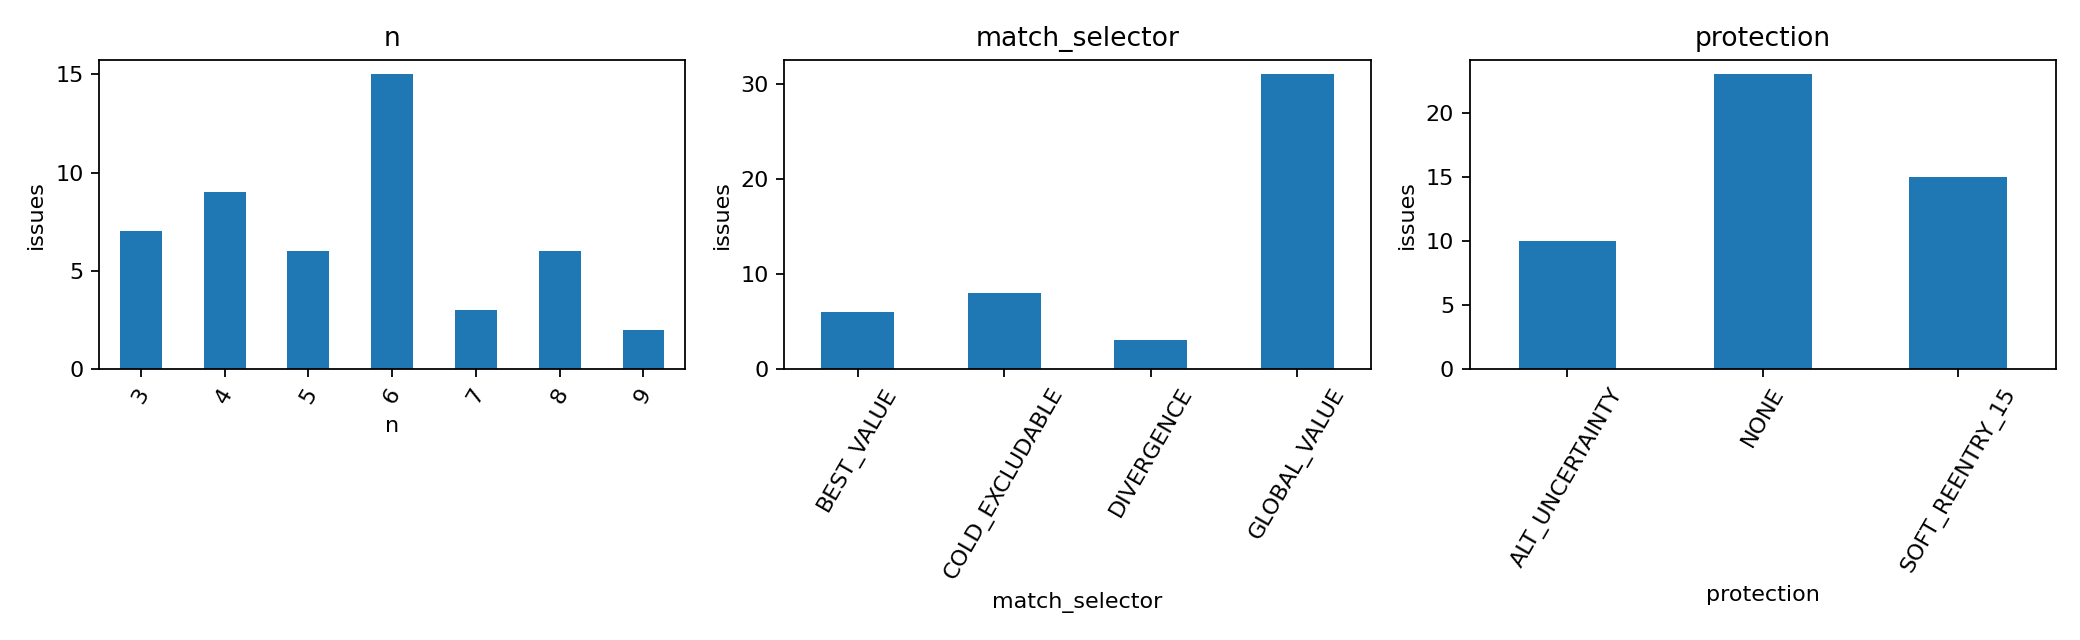

In [5]:
display(pd.read_csv(OUTPUT / 'primary_parameter_distribution.csv')
        .sort_values('allocated_tickets', ascending=False).head(30))
null = pd.read_csv(OUTPUT / 'same_exposure_permutation_2023.csv')
display(null.median_terminal_capital_cny.describe(percentiles=[.05,.5,.95]))
display(Image(filename=str(OUTPUT / 'primary_parameter_distribution.png')))

## Prediction transfer and long-tail seed stability

,target,rows,issues,pooled_spearman,median_within_issue_spearman,positive_within_issue_fraction
0,mean_roi,2160,48,0.308603,0.442875,0.729167
1,positive_probability,2160,48,0.412931,0.546111,0.895833
2,tail_5x_probability,2160,48,0.346543,0.402193,0.937500


,actions,development_vs_2023_spearman,development_top_action,development_top_2023_mean_roi,evaluation_top_action,evaluation_top_mean_roi
0,55,0.166679,N10_K8_SGLOBAL_VALUE_ALL_ORAW_VALUE_GWEIGHTED_...,2.337525,N10_K8_SGLOBAL_VALUE_ALL_ORAW_VALUE_GWEIGHTED_...,2.337525


,count,mean,std,min,5%,50%,95%,max
condition,,,,,,,,
BEST_STATIC_ACTION,31.0,214894.052140,913369.762966,50848.000000,50848.000000,50848.000000,50848.000000,5.136276e+06
FIXED_N7_K512_WOR,31.0,89907.305692,12089.975786,62695.147514,77014.342137,87984.267911,109672.132928,1.238453e+05
IDENTITY_SHUFFLED,31.0,266752.732009,910614.541868,80402.725572,82681.915323,95807.814024,200052.336062,5.170439e+06
JOINT_PRIMARY,31.0,73516.798488,10785.308132,58898.747155,61505.138997,70795.718448,91663.373368,9.948788e+04


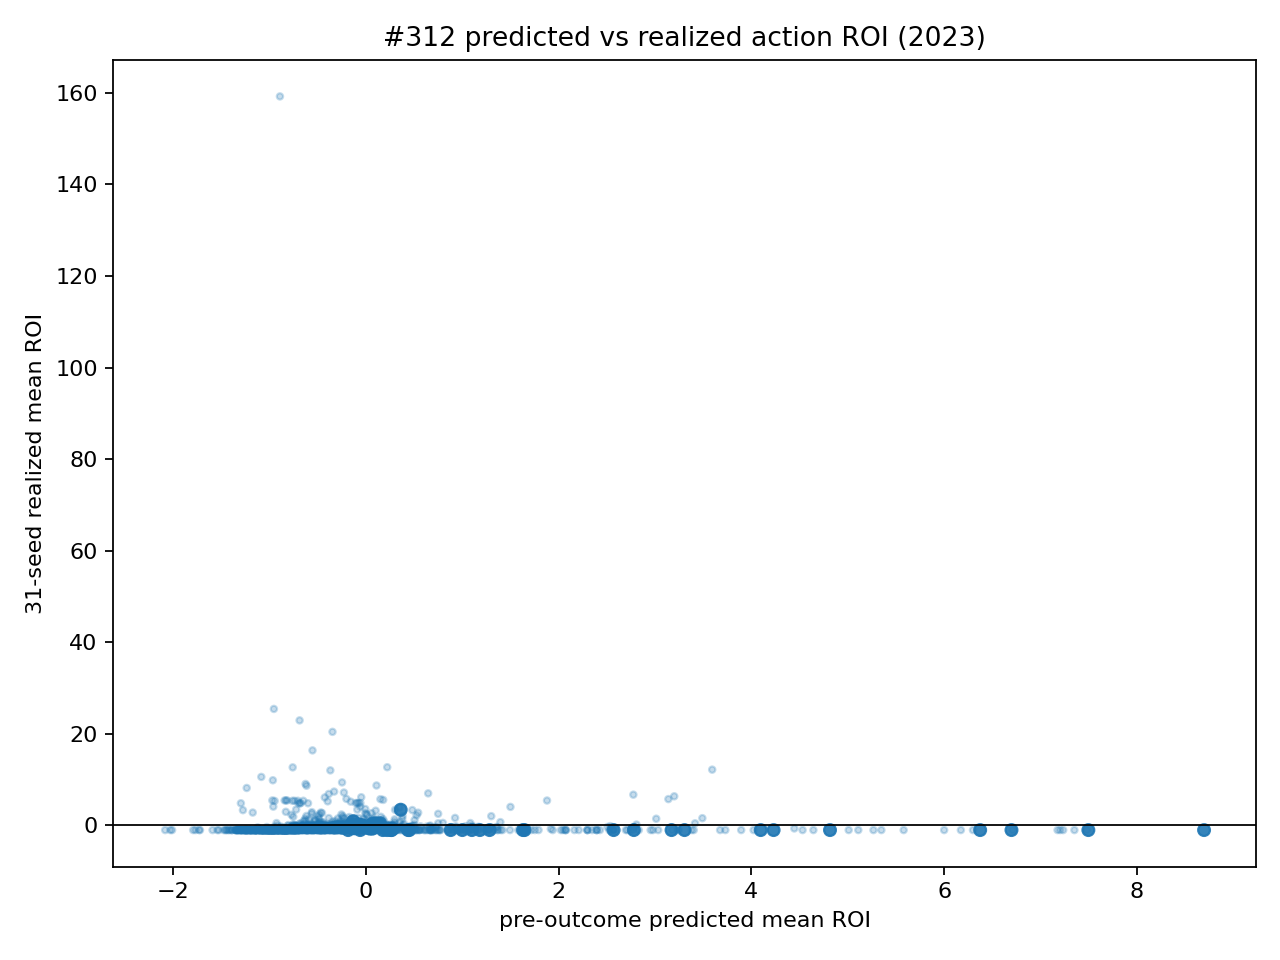

In [6]:
display(pd.read_csv(OUTPUT / 'prediction_diagnostics_2023.csv'))
display(pd.read_csv(OUTPUT / 'static_rank_transfer.csv'))
seed_summary = pd.read_csv(OUTPUT / 'policy_summary_by_seed.csv')
display(seed_summary[seed_summary.condition.isin([
    'JOINT_PRIMARY','IDENTITY_SHUFFLED','FIXED_N7_K512_WOR','BEST_STATIC_ACTION'
])].groupby('condition').terminal_capital_cny.describe(percentiles=[.05,.5,.95]))
display(Image(filename=str(OUTPUT / 'prediction_vs_realized_2023.png')))

## Outcome-exposed factor diagnostics

In [7]:
factor = pd.read_csv(OUTPUT / 'realized_factor_marginals_2023.csv')
for name in ['match_selector','outcome_direction','generator','protection','n','k']:
    display(factor[factor.factor.eq(name)].sort_values('mean_realized_roi', ascending=False))

,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
12,match_selector,BEST_VALUE,192,4,-0.139503,-0.232623,0.302083,0.038642
14,match_selector,DIVERGENCE,528,11,-0.142852,-1.000000,0.142045,0.034641
15,match_selector,GLOBAL_VALUE,1920,40,-0.222415,-0.442273,0.128646,0.034778
13,match_selector,COLD_EXCLUDABLE,384,8,-0.262422,-1.000000,0.122396,0.047799
17,match_selector,LOW_ENTROPY,192,4,-0.328267,-0.472903,0.229167,0.018649
16,match_selector,HYBRID,192,4,-0.351559,-0.418438,0.140625,0.014281


,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
25,outcome_direction,RAW_VALUE,2112,44,-0.186721,-0.457766,0.138258,0.036565
23,outcome_direction,HYBRID,288,6,-0.227171,-0.330511,0.163194,0.015233
24,outcome_direction,MARKET_P,672,14,-0.249490,-0.592741,0.187500,0.031778
22,outcome_direction,DIVERGENCE,336,7,-0.396150,-1.000000,0.098214,0.042243


,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
28,generator,WEIGHTED_WR,1104,23,-0.068949,-0.280629,0.182065,0.019898
27,generator,WEIGHTED_WOR,960,20,-0.177848,-0.272373,0.208333,0.031452
26,generator,TOP_VALUE,1344,28,-0.382210,-1.000000,0.072173,0.048363


,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
31,protection,NONE,1920,40,-0.193166,-0.397257,0.144271,0.035652
29,protection,ALT_DIVERGENCE,288,6,-0.228339,-0.429397,0.156250,0.030578
30,protection,ALT_UNCERTAINTY,336,7,-0.233502,-0.367205,0.220238,0.035618
32,protection,SOFT_REENTRY_05,96,2,-0.261212,-0.262135,0.208333,0.000000
33,protection,SOFT_REENTRY_15,768,16,-0.286939,-1.000000,0.106771,0.036374


,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
7,n,10,48,1,2.337525,-1.000000,0.020833,0.000672
6,n,9,144,3,0.000405,-1.000000,0.284722,0.037634
5,n,8,384,8,-0.086477,-0.254556,0.328125,0.050991
4,n,7,240,5,-0.090645,-0.321508,0.279167,0.044220
3,n,6,480,10,-0.201555,-1.000000,0.110417,0.039919
0,n,3,768,16,-0.293523,-0.390128,0.109375,0.033854
1,n,4,672,14,-0.329434,-0.546624,0.093750,0.029858
2,n,5,672,14,-0.408169,-1.000000,0.093750,0.024242


,factor,level,issue_action_rows,actions,mean_realized_roi,median_realized_roi,positive_issue_action_fraction,mean_tail_5x_probability
8,k,8,528,11,-0.151038,-1.000000,0.104167,0.048021
11,k,512,1104,23,-0.202797,-0.276308,0.180254,0.029307
10,k,128,1200,25,-0.227975,-0.472824,0.149167,0.029758
9,k,32,576,12,-0.318295,-1.000000,0.112847,0.041219


## Decision boundary

The primary claim is judged against fixed/static controls on inherited exact-B0
common support, paired physical ticket seeds, factor resets, a same-exposure
permutation null and ex-largest performance. #306 is interface-only context,
not an accepted positive baseline. Ticket seeds remain nested within Beijing
issues. 2024+ is sealed.